# Notebook 05 — Transformer: Training & Evaluation

**Model:** Transformer Encoder (d_model=64, 4 heads, 3 layers, mean pooling)  
**Dataset:** NASA CMAPSS — FD001  

### Why the Transformer is the primary model
- Reads all 30 cycles simultaneously — no vanishing gradient across long sequences
- Attention mechanism directly shows which cycles influenced each prediction (free XAI)
- Published RMSE ~13.2 on FD001 — best among standard architectures
- Expected to show larger advantage over LSTM/CNN on FD003/FD004 (complex fault modes)


## 0 · Imports

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path('..').resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import json

from src.utils.config import DATA_PROC, OUT_MODELS, OUT_FIGURES, OUT_RESULTS
from src.models.transformer import TransformerModel
from src.utils.trainer import train, load_splits
from src.evaluation.metrics import all_metrics

sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 120, 'figure.facecolor': 'white'})

SUBSET = 'FD001'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device  : {DEVICE}')
print(f'PyTorch : {torch.__version__}')

Device  : cpu
PyTorch : 2.12.1+cpu


## 1 · Verify data

In [2]:
proc = DATA_PROC / SUBSET
print(f'Checking: {proc}\n')
for name in ['X_train','y_train','X_val','y_val','X_test','y_test']:
    p = proc / f'{name}.npy'
    if p.exists():
        a = np.load(p)
        print(f'  {name:12s}  {str(a.shape):20s}')
    else:
        print(f'  MISSING: {p}')

Checking: C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\data\processed\FD001

  X_train       (15332, 30, 14)     
  y_train       (15332,)            
  X_val         (2399, 30, 14)      
  y_val         (2399,)             
  X_test        (100, 30, 14)       
  y_test        (100,)              


## 2 · Architecture and parameter comparison

In [3]:
model = TransformerModel()
print(model)
print(f'\nTransformer parameters : {model.count_parameters():,}')
print(f'LSTM parameters        : ~234,625')
print(f'CNN parameters         : ~{sum(p.numel() for p in __import__("src.models.cnn1d", fromlist=["CNN1DModel"]).CNN1DModel().parameters() if p.requires_grad):,}')

# Sanity check forward pass
dummy = torch.randn(4, 30, 14)
with torch.no_grad():
    out = model(dummy)
print(f'\nForward pass: {dummy.shape} → {out.shape} ✓')

TransformerModel(
  (input_proj): Linear(in_features=14, out_features=64, bias=True)
  (pos_enc): PositionalEncoding(
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-2): 3 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=256, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=256, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (head): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropo

## 3 · Train

Transformer trains slower than CNN but faster than LSTM on CPU.  
**Expected time on CPU: 10–20 minutes.**

In [4]:
results = train(model_name='transformer', subset=SUBSET)
print('\nTraining complete.')


  Model   : TRANSFORMER
  Subset  : FD001
  Device  : cpu
  Parameters : 155,137
  Train batches : 60  |  Val batches : 10
  Ep   1/100  train_mse=7593.6893  val_rmse=75.7589  lr=1.00e-03  [26s]
  Ep   5/100  train_mse=456.3172  val_rmse=19.4481  lr=1.00e-03  [133s]
  Ep  10/100  train_mse=245.5174  val_rmse=18.3214  lr=1.00e-03  [272s]
  Ep  15/100  train_mse=219.4584  val_rmse=12.7361  lr=1.00e-03  [516s]
  Ep  20/100  train_mse=212.1906  val_rmse=14.8189  lr=1.00e-03  [817s]
  Ep  25/100  train_mse=198.4429  val_rmse=14.8661  lr=5.00e-04  [1081s]
  Ep  30/100  train_mse=192.0404  val_rmse=14.7702  lr=5.00e-04  [1392s]

  Early stopping at epoch 30 (no improvement for 15 epochs)

  ── Test Results (TRANSFORMER, FD001) ──
RMSE=13.696  MAE=10.218  R²=0.8832  NASA=294.5
  Best val RMSE : 12.7361
  Total time    : 1392s
  Results saved  → C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\results\transformer_FD001_results.json
  Checkpoint     → C:\Users\rumma\OneDrive\De

## 4 · Training curves

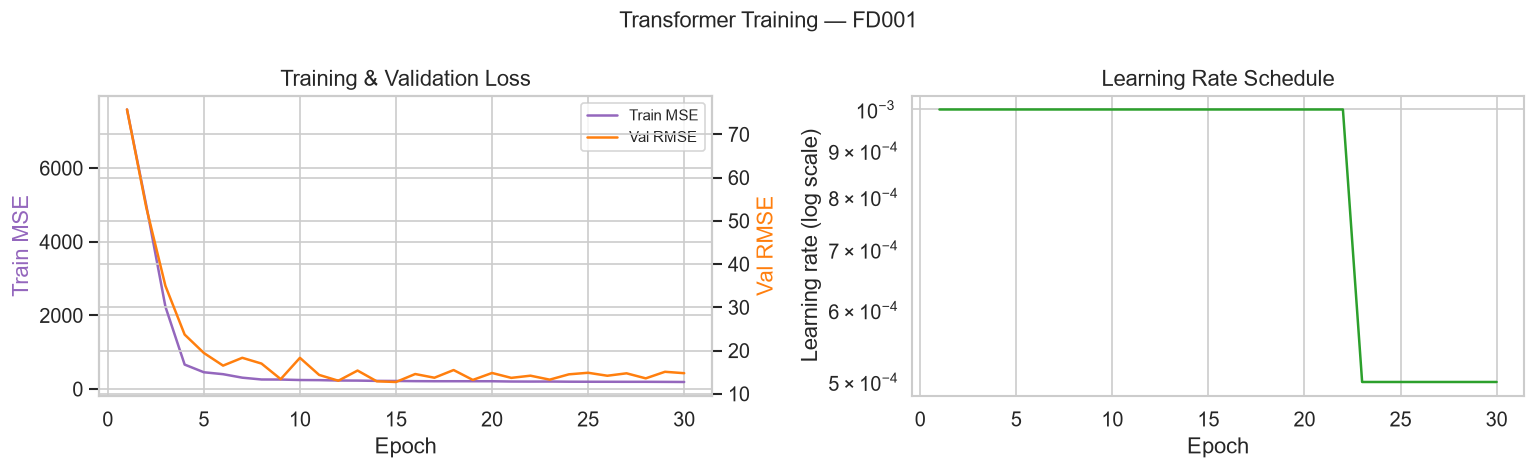

Best val RMSE : 12.7361
Epochs run    : 30


In [5]:
log       = results['log']
epochs    = [r['epoch']     for r in log]
train_mse = [r['train_mse'] for r in log]
val_rmse  = [r['val_rmse']  for r in log]
lrs       = [r['lr']        for r in log]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax  = axes[0]
ax2 = ax.twinx()
ax.plot(epochs, train_mse, color='#9467bd', lw=1.5, label='Train MSE')
ax2.plot(epochs, val_rmse, color='#ff7f0e', lw=1.5, label='Val RMSE')
ax.set_xlabel('Epoch')
ax.set_ylabel('Train MSE', color='#9467bd')
ax2.set_ylabel('Val RMSE', color='#ff7f0e')
ax.set_title('Training & Validation Loss')
l1, lb1 = ax.get_legend_handles_labels()
l2, lb2 = ax2.get_legend_handles_labels()
ax.legend(l1+l2, lb1+lb2, fontsize=9)

axes[1].semilogy(epochs, lrs, color='#2ca02c', lw=1.5)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Learning rate (log scale)')
axes[1].set_title('Learning Rate Schedule')

fig.suptitle(f'Transformer Training — {SUBSET}', fontsize=13)
plt.tight_layout()
plt.savefig(OUT_FIGURES / f'transformer_{SUBSET}_training_curves.png', bbox_inches='tight')
plt.show()
print(f'Best val RMSE : {results["best_val_rmse"]:.4f}')
print(f'Epochs run    : {results["epochs_run"]}')

## 5 · Test metrics

In [6]:
m = results['test']
print(f'\n{" Test Results — Transformer, " + SUBSET + " ":=^52}')
print(f'  RMSE       : {m["RMSE"]:.3f}  cycles')
print(f'  MAE        : {m["MAE"]:.3f}  cycles')
print(f'  R²         : {m["R2"]:.4f}')
print(f'  NASA Score : {m["NASA_Score"]:.1f}  (lower = better)')
print('='*52)


======== Test Results — Transformer, FD001 =========
  RMSE       : 13.696  cycles
  MAE        : 10.218  cycles
  R²         : 0.8832
  NASA Score : 294.5  (lower = better)


## 6 · Predicted vs actual RUL

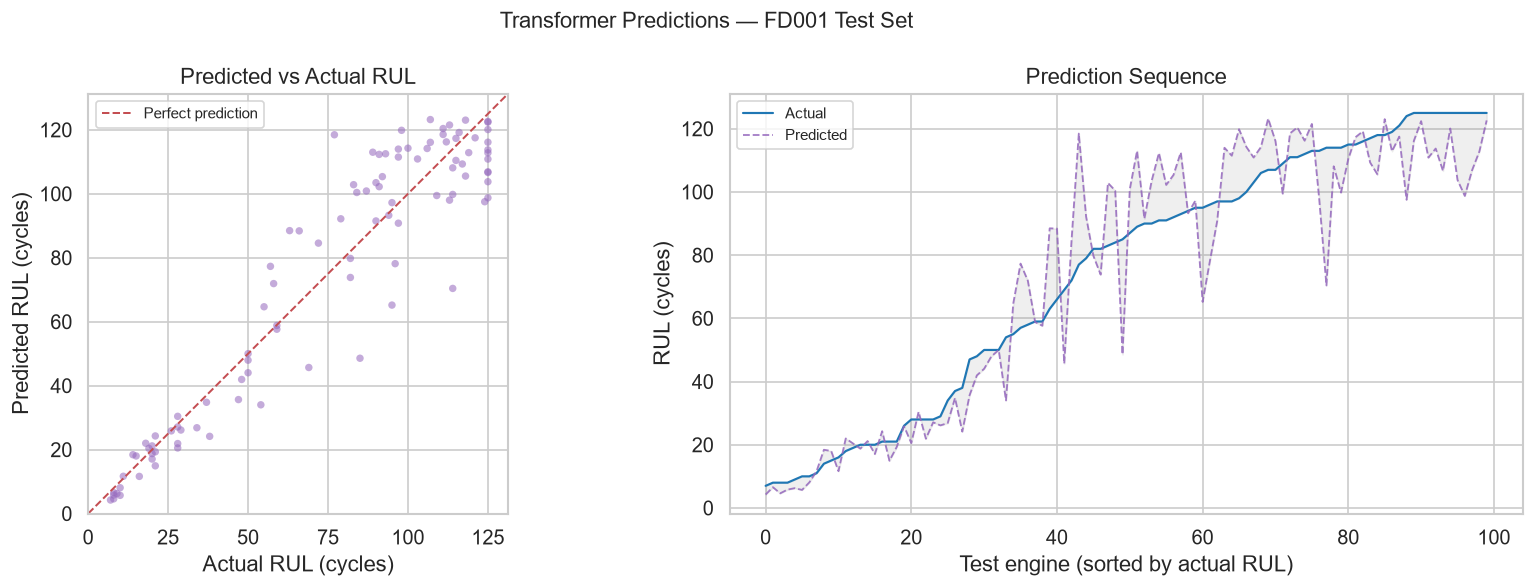

In [7]:
_, _, te_loader, y_test = load_splits(SUBSET, DEVICE)

best_model = TransformerModel().to(DEVICE)
best_model.load_state_dict(
    torch.load(OUT_MODELS / f'transformer_{SUBSET}_best.pt',
               map_location=DEVICE, weights_only=True)
)
best_model.eval()

preds = []
with torch.no_grad():
    for X_b, _ in te_loader:
        preds.append(best_model(X_b.to(DEVICE)).cpu().numpy())
preds = np.concatenate(preds)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.scatter(y_test, preds, alpha=0.55, s=20, color='#9467bd', edgecolors='none')
lim = [0, max(y_test.max(), preds.max()) * 1.05]
ax.plot(lim, lim, 'r--', lw=1.2, label='Perfect prediction')
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel('Actual RUL (cycles)')
ax.set_ylabel('Predicted RUL (cycles)')
ax.set_title('Predicted vs Actual RUL')
ax.legend(fontsize=9); ax.set_aspect('equal')

idx = np.argsort(y_test)
axes[1].plot(y_test[idx], label='Actual',    color='#1f77b4', lw=1.3)
axes[1].plot(preds[idx],  label='Predicted', color='#9467bd', lw=1.1, ls='--', alpha=0.85)
axes[1].fill_between(range(len(y_test)), y_test[idx], preds[idx],
                     alpha=0.12, color='grey')
axes[1].set_xlabel('Test engine (sorted by actual RUL)')
axes[1].set_ylabel('RUL (cycles)')
axes[1].set_title('Prediction Sequence')
axes[1].legend(fontsize=9)

fig.suptitle(f'Transformer Predictions — {SUBSET} Test Set', fontsize=13)
plt.tight_layout()
plt.savefig(OUT_FIGURES / f'transformer_{SUBSET}_predictions.png', bbox_inches='tight')
plt.show()

## 7 · Error analysis

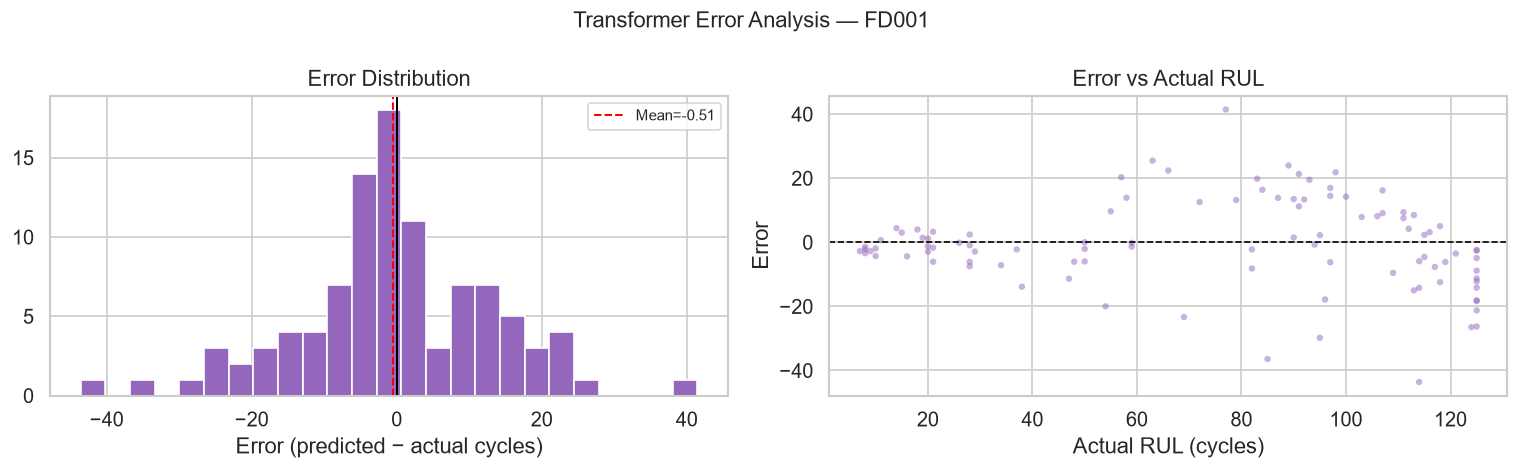

Mean error (bias)   : -0.511 cycles
Within ±10 cycles   : 60.0%
Within ±20 cycles   : 86.0%
Early predictions   : 43.0%  (risky)
Late predictions    : 57.0%  (conservative)


In [8]:
errors = preds - y_test

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(errors, bins=25, color='#9467bd', edgecolor='white')
axes[0].axvline(0, color='black', lw=1.2)
axes[0].axvline(errors.mean(), color='red', lw=1.2, ls='--',
                label=f'Mean={errors.mean():.2f}')
axes[0].set_xlabel('Error (predicted − actual cycles)')
axes[0].set_title('Error Distribution')
axes[0].legend(fontsize=9)

axes[1].scatter(y_test, errors, alpha=0.5, s=15, color='#9467bd', edgecolors='none')
axes[1].axhline(0, color='black', ls='--', lw=1)
axes[1].set_xlabel('Actual RUL (cycles)')
axes[1].set_ylabel('Error')
axes[1].set_title('Error vs Actual RUL')

fig.suptitle(f'Transformer Error Analysis — {SUBSET}', fontsize=13)
plt.tight_layout()
plt.savefig(OUT_FIGURES / f'transformer_{SUBSET}_errors.png', bbox_inches='tight')
plt.show()

print(f'Mean error (bias)   : {errors.mean():.3f} cycles')
print(f'Within ±10 cycles   : {(np.abs(errors)<=10).mean()*100:.1f}%')
print(f'Within ±20 cycles   : {(np.abs(errors)<=20).mean()*100:.1f}%')
print(f'Early predictions   : {(errors>0).mean()*100:.1f}%  (risky)')
print(f'Late predictions    : {(errors<0).mean()*100:.1f}%  (conservative)')

## 8 · Full 3-model comparison table

In [10]:
models_to_compare = ['lstm', 'cnn1d', 'transformer']
labels = {'lstm': 'LSTM', 'cnn1d': '1D-CNN', 'transformer': 'Transformer'}
metrics_list = ['RMSE', 'MAE', 'R2', 'NASA_Score']

print(f'\n{" Full Model Comparison — FD001 ":=^60}')
print(f'{"Model":<15} {"RMSE":>10} {"MAE":>10} {"R2":>10} {"NASA":>12}')
print('-' * 60)

results_data = {}
for m_name in models_to_compare:
    path = OUT_RESULTS / f'{m_name}_{SUBSET}_results.json'
    if path.exists():
        m = json.load(open(path))['test']
        results_data[m_name] = m
        print(f'  {labels[m_name]:<13} '
              f'{m["RMSE"]:>10.3f} '
              f'{m["MAE"]:>10.3f} '
              f'{m["R2"]:>10.4f} '
              f'{m["NASA_Score"]:>12.1f}')
    else:
        print(f'  {labels[m_name]:<13}  results not found — run the training notebook first')

print('-' * 60)
print('  Published baselines (FD001 RMSE):')
print('    LSTM        (Zheng et al., 2017) : ~16.1')
print('    CNN1D         (Babu et al., 2016)  : ~18.5')
print('    Transformer (Fan et al., 2020)   : ~13.2')
print('='*60)


============== Full Model Comparison — FD001 ===============
Model                 RMSE        MAE         R2         NASA
------------------------------------------------------------
  LSTM              12.876      9.824     0.8968        232.8
  1D-CNN            19.506     15.350     0.7631        995.0
  Transformer       13.696     10.218     0.8832        294.5
------------------------------------------------------------
  Published baselines (FD001 RMSE):
    LSTM        (Zheng et al., 2017) : ~16.1
    CNN1D         (Babu et al., 2016)  : ~18.5
    Transformer (Fan et al., 2020)   : ~13.2


## 9 · Attention weight visualisation

Preview of the XAI phase — which cycles did the Transformer attend to when making predictions?
This uses `get_attention_weights()` from the model to extract raw attention maps.

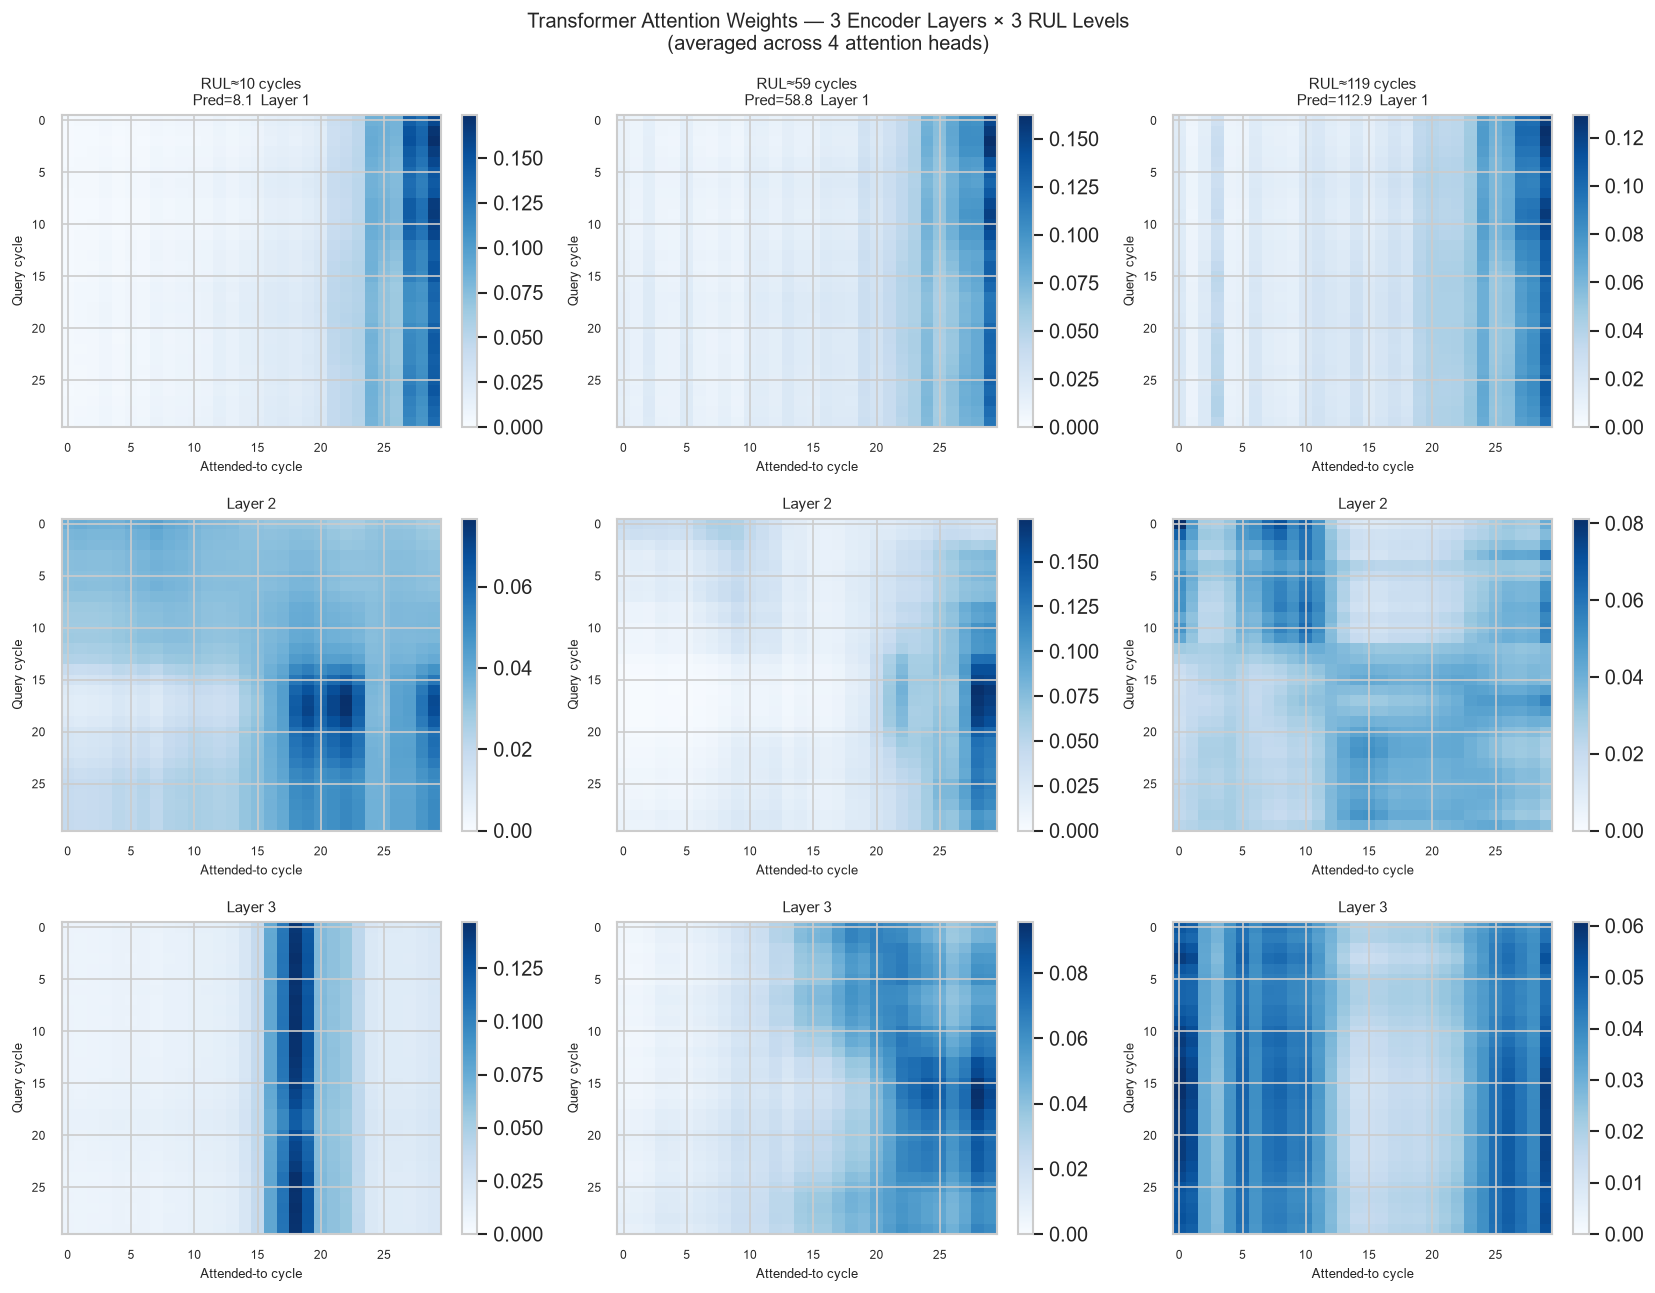

Each cell [i, j] shows how much cycle i attended to cycle j.
Bright cells = high attention. This is the raw XAI signal.
Full attention analysis comes in Phase 5 — XAI implementation.


In [ ]:
# Load test data and pick 3 engines: low RUL, mid RUL, high RUL
X_test = np.load(DATA_PROC / SUBSET / 'X_test.npy')
y_test_raw = np.load(DATA_PROC / SUBSET / 'y_test.npy')

# Find engines closest to RUL = 10, 60, 120
target_ruls = [10, 60, 120]
selected_idx = [np.argmin(np.abs(y_test_raw - t)) for t in target_ruls]

fig, axes = plt.subplots(3, 3, figsize=(14, 11))

for col, (idx, target) in enumerate(zip(selected_idx, target_ruls)):
    window   = torch.tensor(X_test[idx:idx+1], dtype=torch.float32)
    actual   = y_test_raw[idx]
    pred_val = preds[idx]

    # Get attention weights for all 3 encoder layers
    attn_list = best_model.get_attention_weights(window)

    for row, layer_attn in enumerate(attn_list):
        # layer_attn shape: (1, 4, 30, 30)
        # Average across 4 attention heads for visualisation
        avg_attn = layer_attn[0].mean(dim=0).numpy()   # (30, 30)

        ax = axes[row][col]
        im = ax.imshow(avg_attn, cmap='Blues', aspect='auto', vmin=0)
        ax.set_xlabel('Attended-to cycle', fontsize=8)
        ax.set_ylabel('Query cycle', fontsize=8)
        ax.tick_params(labelsize=7)

        if row == 0:
            ax.set_title(
                f'RUL≈{actual:.0f} cycles\n'
                f'Pred={pred_val:.1f}  Layer 1',
                fontsize=9
            )
        else:
            ax.set_title(f'Layer {row+1}', fontsize=9)

        plt.colorbar(im, ax=ax, fraction=0.04)

fig.suptitle(
    'Transformer Attention Weights — 3 Encoder Layers × 3 RUL Levels\n'
    '(averaged across 4 attention heads)',
    fontsize=12
)
plt.tight_layout()
plt.savefig(OUT_FIGURES / f'transformer_{SUBSET}_attention_preview.png', bbox_inches='tight')
plt.show()

print('Each cell [i, j] shows how much cycle i attended to cycle j.')
print('Bright cells = high attention. This is the raw XAI signal.')


In [15]:
m = results['test']
print(f"""

   TRANSFORMER — {SUBSET} RESULTS                        

   RMSE       : {m['RMSE']:>8.3f} cycles                 
   MAE        : {m['MAE']:>8.3f} cycles                  
   R²         : {m['R2']:>8.4f}                          
   NASA Score : {m['NASA_Score']:>10.1f}                 

""")



   TRANSFORMER — FD001 RESULTS                        

   RMSE       :   13.696 cycles                 
   MAE        :   10.218 cycles                  
   R²         :   0.8832                          
   NASA Score :      294.5                 


